# Brain Tumor MRI Image Classification
**Complete notebook:** dataset discovery, extraction, EDA (U/B/M), optional CNN training, evaluation, and deployment preparation.

**Medical disclaimer:** educational prototype only; not for diagnosis or treatment. Run cells top-to-bottom. EDA runs by default; model training is opt-in in the configuration cell.

**Insight reporting:** each EDA chart now prints data-derived findings, potential positive impact, and a risk statement. These findings are generated only when you run the notebook against your actual dataset.

In [ ]:
# 1. Required imports and reproducibility
import os, sys, random, zipfile, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Python:", sys.version.split()[0])
print("Working directory:", Path.cwd())
print("Core libraries imported.")


Python: 3.13.15
Working directory: /content
Core libraries imported.


In [ ]:
# 2. Robust dataset discovery and configuration
TRAIN_ZIP = "train-20261012T034245Z-1-001.zip"
VALID_ZIP = "valid-20261012T034250Z-1-001.zip"
TEST_ZIP  = "test-20261012T034237Z-1-001.zip"
ZIP_NAMES = [TRAIN_ZIP, VALID_ZIP, TEST_ZIP]
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5
RUN_MODEL_TRAINING = True  # Full run: trains CNN and MobileNetV2.
EXTRACT_DIR = Path("/content/brain_tumor_extracted") if Path("/content").exists() else Path.cwd() / "brain_tumor_extracted"

# Search likely roots first, including filesystem root (the uploaded files may appear there).
def locate_zip(filename):
    roots = [Path("/"), Path("/content"), Path.cwd()]
    seen = set()
    for root in roots:
        try:
            search_root = root if root != Path("/") else Path("/")
            # Search exact filename; ignore permission errors.
            for p in search_root.rglob(filename):
                if p.is_file():
                    return p.resolve()
        except (PermissionError, OSError):
            continue
    return None

found = {name: locate_zip(name) for name in ZIP_NAMES}
# Fallback: find similarly named archives if Colab has altered the filename.
for split, name in [("train", TRAIN_ZIP), ("valid", VALID_ZIP), ("test", TEST_ZIP)]:
    if found[name] is None:
        for root in [Path("/content"), Path("/")]:
            try:
                base = root if root == Path("/content") else Path("/")
                candidates = [p for p in base.rglob("*.zip") if p.is_file() and split in p.name.lower()]
                if candidates:
                    found[name] = candidates[0].resolve()
                    break
            except (PermissionError, OSError):
                pass

print("Archive search:")
for name, path in found.items():
    print(name, "->", path if path else "NOT FOUND")
missing = [name for name, path in found.items() if path is None]
if missing:
    print("Root listing:", os.listdir("/"))
    if Path("/content").exists():
        print("/content listing:", os.listdir("/content"))
    raise FileNotFoundError("Missing dataset archives: " + ", ".join(missing) +
                            ". Check the Colab Files panel and set the full paths in this cell.")
DATA_DIR = found[TRAIN_ZIP].parent
print("Dataset directory:", DATA_DIR)


Archive search:
train-20261012T034245Z-1-001.zip -> /content/train-20261012T034245Z-1-001.zip
valid-20261012T034250Z-1-001.zip -> /content/valid-20261012T034250Z-1-001.zip
test-20261012T034237Z-1-001.zip -> /content/test-20261012T034237Z-1-001.zip
Dataset directory: /content


In [ ]:
# 3. Extract archives into separate split folders with basic integrity checks
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIRS = {}
for split, name in [("train", TRAIN_ZIP), ("valid", VALID_ZIP), ("test", TEST_ZIP)]:
    target = EXTRACT_DIR / split
    target.mkdir(parents=True, exist_ok=True)
    try:
        with zipfile.ZipFile(found[name], "r") as zf:
            bad = zf.testzip()
            if bad:
                raise zipfile.BadZipFile(f"Corrupt archive member: {bad}")
            zf.extractall(target)
        SPLIT_DIRS[split] = target
        print(split, "extracted to", target)
    except (OSError, zipfile.BadZipFile) as exc:
        raise RuntimeError(f"Failed to extract {found[name]}: {exc}") from exc


train extracted to /content/brain_tumor_extracted/train
valid extracted to /content/brain_tumor_extracted/valid
test extracted to /content/brain_tumor_extracted/test


In [ ]:
# 4. Discover image files and infer class labels from folder names
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
def image_paths(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)

def infer_label(path, split_root):
    excluded = {"train", "valid", "validation", "test", "images", "image", "data", "dataset"}
    for parent in path.parents:
        if parent == Path(split_root).parent:
            break
        label = parent.name.strip().lower().replace(" ", "_").replace("-", "_")
        if label and label not in excluded:
            return label
        if parent == Path(split_root):
            break
    return path.parent.name.strip().lower().replace(" ", "_").replace("-", "_")

rows = []
for split, root in SPLIT_DIRS.items():
    paths = image_paths(root)
    print(f"{split}: {len(paths)} image files")
    for p in paths:
        rows.append({"split": split, "path": str(p), "filename": p.name, "label": infer_label(p, root)})
df = pd.DataFrame(rows)
if df.empty:
    raise ValueError("No images found. Check archive contents and class-folder structure.")

def normalize_label(x):
    x = str(x).lower().replace("-", "_").replace(" ", "_")
    aliases = {"notumor":"no_tumor", "no_tumour":"no_tumor", "no_tumor":"no_tumor",
               "glioma_tumor":"glioma", "meningioma_tumor":"meningioma", "pituitary_tumor":"pituitary"}
    return aliases.get(x, x)
df["label"] = df["label"].map(normalize_label)
display(df.head())
print("Dataset rows:", len(df), "| classes:", sorted(df.label.unique()))


train: 1695 image files
valid: 502 image files
test: 246 image files


,split,path,filename,label
0,train,/content/brain_tumor_extracted/train/train/gli...,Tr-gl_0011_jpg.rf.61e213cb5a0f97fedd1bacd0428c...,glioma
1,train,/content/brain_tumor_extracted/train/train/gli...,Tr-gl_0013_jpg.rf.312d7ef8d55655cbf02c4143dfef...,glioma
2,train,/content/brain_tumor_extracted/train/train/gli...,Tr-gl_0014_jpg.rf.1c9a1de19711c94e45210faa7473...,glioma
3,train,/content/brain_tumor_extracted/train/train/gli...,Tr-gl_0015_jpg.rf.13077910f13033d4bbdedda8b91c...,glioma
4,train,/content/brain_tumor_extracted/train/train/gli...,Tr-gl_0016_jpg.rf.85a74661631af6d62d25e50e62d3...,glioma


Dataset rows: 2443 | classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [ ]:
# 5. Image integrity checks and image-level statistics
def readable(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except (UnidentifiedImageError, OSError, ValueError):
        return False

df["readable"] = df["path"].map(readable)
print("Unreadable images:", int((~df.readable).sum()))
df = df[df.readable].copy().reset_index(drop=True)
if df.empty:
    raise ValueError("No readable images remain after data-quality checks.")

stats = []
for r in df.itertuples(index=False):
    try:
        with Image.open(r.path) as im:
            w, h = im.size
            gray = np.asarray(im.convert("L").resize((128,128)), dtype=np.float32)
            stats.append({"path":r.path, "split":r.split, "label":r.label, "width":w, "height":h,
                          "aspect_ratio":w/h if h else np.nan, "brightness":float(gray.mean()),
                          "contrast":float(gray.std()), "file_size_kb":Path(r.path).stat().st_size/1024})
    except (UnidentifiedImageError, OSError, ValueError):
        continue
stats_df = pd.DataFrame(stats)
if stats_df.empty:
    raise ValueError("Could not calculate image statistics.")
display(df.groupby(["split","label"]).size().unstack(fill_value=0))
display(stats_df.describe())


Unreadable images: 0


label,glioma,meningioma,no_tumor,pituitary
split,,,,
test,80,63,49,54
train,564,358,335,438
valid,161,124,99,118


,width,height,aspect_ratio,brightness,contrast,file_size_kb
count,2443.0,2443.0,2443.0,2443.000000,2443.000000,2443.000000
mean,640.0,640.0,1.0,43.767859,43.383378,31.165728
std,0.0,0.0,0.0,18.624187,11.229331,9.092209
min,640.0,640.0,1.0,9.762878,21.671425,16.444336
25%,640.0,640.0,1.0,29.538574,36.230844,24.048828
50%,640.0,640.0,1.0,40.050171,40.981564,30.009766
75%,640.0,640.0,1.0,53.106506,47.190020,36.708008
max,640.0,640.0,1.0,137.725708,90.768669,121.681641


# Exploratory Data Analysis — UBM
Each chart is followed by the rationale, how to interpret its actual output, and potential business impact. Do not report assumed findings; write conclusions from the charts generated on your data.

In [ ]:
# Chart helper
def show(title, xlabel=None, ylabel=None, rotation=0):
    plt.title(title)
    if xlabel: plt.xlabel(xlabel)
    if ylabel: plt.ylabel(ylabel)
    if rotation: plt.xticks(rotation=rotation, ha="right")
    plt.tight_layout()
    plt.show()


In [ ]:
# Data-driven insight helpers
# These functions print findings calculated from the actual dataset, rather than generic placeholders.
def report_insight(chart_name, finding, positive_impact, risk):
    print(f"INSIGHT — {chart_name}")
    print(f"Finding: {finding}")
    print(f"Potential positive business impact: {positive_impact}")
    print(f"Potential negative impact / risk: {risk}")
    print("-" * 90)

def pct(part, whole):
    return (100.0 * part / whole) if whole else 0.0

print("Insight reporting helpers are ready. Each chart cell below prints findings based on the loaded data.")


Insight reporting helpers are ready. Each chart cell below prints findings based on the loaded data.


### U1 — Image count by class

**Why this chart?** A bar chart clearly compares class sizes. Identify the largest and smallest classes. Class imbalance can bias a model; monitor class-wise recall and consider class weights only if justified.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

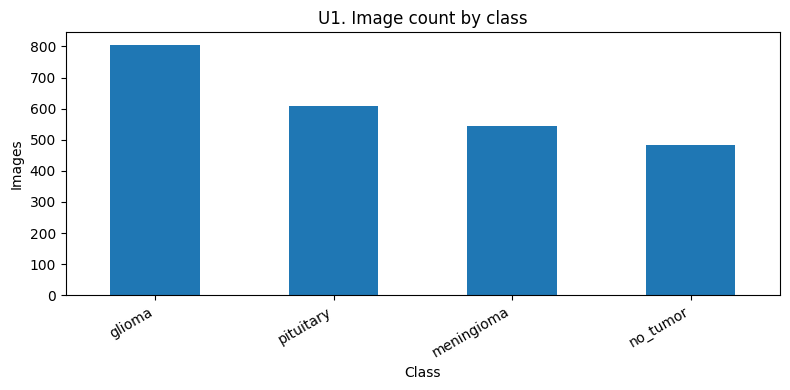

INSIGHT — U1 — Image count by class
Finding: glioma has 805 images (33.0%); no_tumor has 483 (19.8%). Largest/smallest ratio = 1.67x.
Potential positive business impact: Use class-wise recall and macro-F1; consider class weights only if imbalance materially affects model performance.
Potential negative impact / risk: The smaller class may be under-learned; confirm using test-set recall rather than assuming imbalance causes errors.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(8,4)); df.label.value_counts().plot(kind="bar"); show("U1. Image count by class","Class","Images",30)


_counts = df["label"].value_counts()
_largest, _smallest = _counts.idxmax(), _counts.idxmin()
report_insight("U1 — Image count by class",
    f"{_largest} has {_counts[_largest]} images ({pct(_counts[_largest], len(df)):.1f}%); {_smallest} has {_counts[_smallest]} ({pct(_counts[_smallest], len(df)):.1f}%). Largest/smallest ratio = {_counts[_largest]/_counts[_smallest]:.2f}x.",
    "Use class-wise recall and macro-F1; consider class weights only if imbalance materially affects model performance.",
    "The smaller class may be under-learned; confirm using test-set recall rather than assuming imbalance causes errors.")


### U2 — Image count by split

**Why this chart?** A bar chart checks the distribution of images across train, validation, and test. Unexpectedly small splits can make metrics unstable; keep test data independent.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

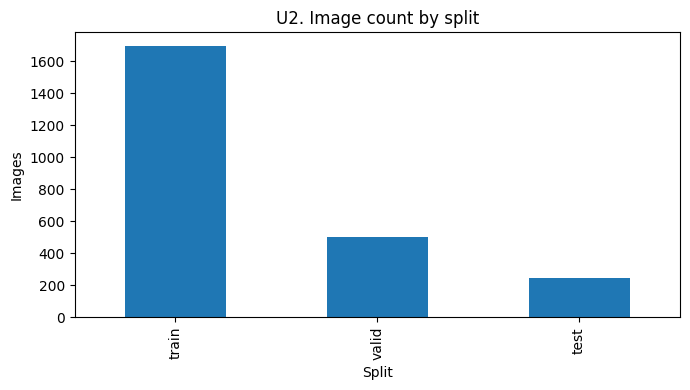

INSIGHT — U2 — Image count by split
Finding: Observed split counts: train=1695 (69.4%), valid=502 (20.5%), test=246 (10.1%).
Potential positive business impact: Adequate validation and test samples support more stable model selection and final evaluation.
Potential negative impact / risk: A small test split can make performance estimates noisy; do not tune on the test set.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(7,4)); df.split.value_counts().reindex(["train","valid","test"]).dropna().plot(kind="bar"); show("U2. Image count by split","Split","Images")


_sc = df["split"].value_counts()
_report = ", ".join(f"{k}={v} ({pct(v, len(df)):.1f}%)" for k,v in _sc.items())
report_insight("U2 — Image count by split",
    f"Observed split counts: {_report}.",
    "Adequate validation and test samples support more stable model selection and final evaluation.",
    "A small test split can make performance estimates noisy; do not tune on the test set.")


### U3 — Original image width

**Why this chart?** A histogram reveals resolution variability. Large variation supports a consistent resize step, while resizing should preserve diagnostically relevant detail.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

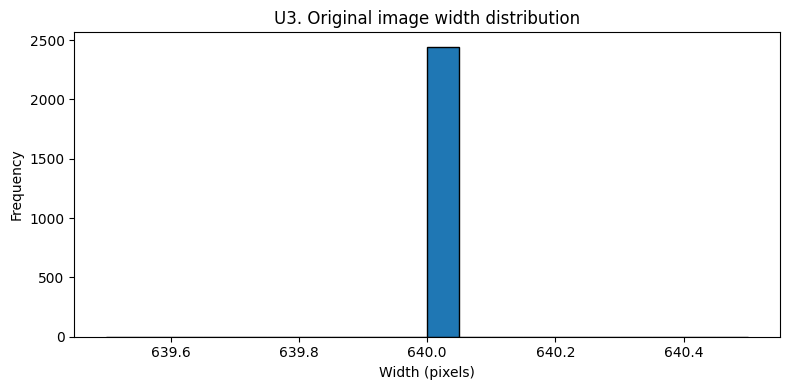

INSIGHT — U3 — Original image width
Finding: Width ranges from 640 to 640 pixels; median=640, IQR=0.
Potential positive business impact: A consistent input size makes model batching reproducible.
Potential negative impact / risk: Resizing very small or unusually large images may lose details; inspect outliers and document preprocessing.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(8,4)); plt.hist(stats_df.width,bins=20,edgecolor="black"); show("U3. Original image width distribution","Width (pixels)","Frequency")


report_insight("U3 — Original image width",
    f"Width ranges from {stats_df.width.min()} to {stats_df.width.max()} pixels; median={stats_df.width.median():.0f}, IQR={stats_df.width.quantile(.75)-stats_df.width.quantile(.25):.0f}.",
    "A consistent input size makes model batching reproducible.",
    "Resizing very small or unusually large images may lose details; inspect outliers and document preprocessing.")


### U4 — Original image height

**Why this chart?** A histogram reveals height variability. Combined with width, it informs whether resizing/aspect-ratio handling is needed.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

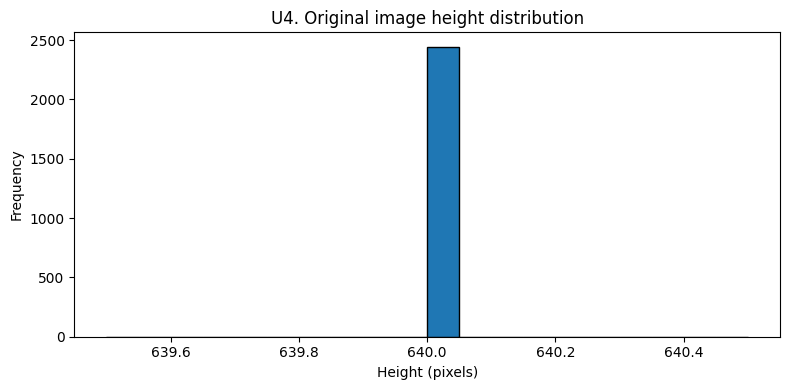

INSIGHT — U4 — Original image height
Finding: Height ranges from 640 to 640 pixels; median=640, IQR=0.
Potential positive business impact: Consistent preprocessing reduces input-shape issues during training and deployment.
Potential negative impact / risk: Strong resolution variation can alter visible details after resizing; inspect outliers.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(8,4)); plt.hist(stats_df.height,bins=20,edgecolor="black"); show("U4. Original image height distribution","Height (pixels)","Frequency")


report_insight("U4 — Original image height",
    f"Height ranges from {stats_df.height.min()} to {stats_df.height.max()} pixels; median={stats_df.height.median():.0f}, IQR={stats_df.height.quantile(.75)-stats_df.height.quantile(.25):.0f}.",
    "Consistent preprocessing reduces input-shape issues during training and deployment.",
    "Strong resolution variation can alter visible details after resizing; inspect outliers.")


### U5 — Brightness distribution

**Why this chart?** A histogram summarizes average grayscale intensity. Extreme brightness differences may reflect acquisition conditions and can harm generalization if preprocessing is inconsistent.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

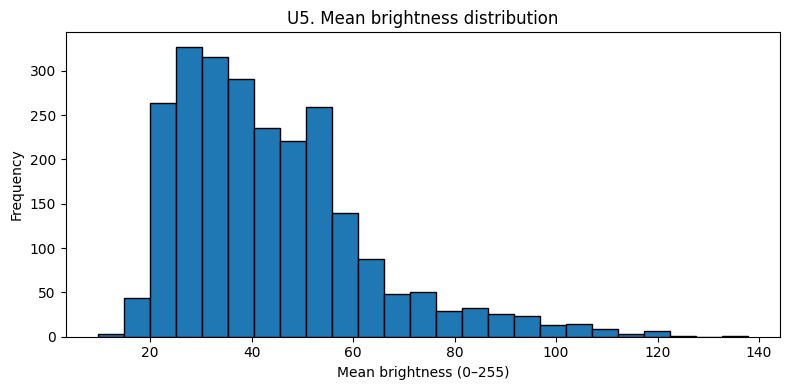

INSIGHT — U5 — Mean brightness
Finding: Mean brightness median=40.1/255; 10th–90th percentile range=24.3–66.9.
Potential positive business impact: Brightness statistics help identify whether consistent normalization should be considered.
Potential negative impact / risk: If brightness differs by scanner or split, the model may learn acquisition artifacts instead of robust patterns.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(8,4)); plt.hist(stats_df.brightness,bins=25,edgecolor="black"); show("U5. Mean brightness distribution","Mean brightness (0–255)","Frequency")


report_insight("U5 — Mean brightness",
    f"Mean brightness median={stats_df.brightness.median():.1f}/255; 10th–90th percentile range={stats_df.brightness.quantile(.1):.1f}–{stats_df.brightness.quantile(.9):.1f}.",
    "Brightness statistics help identify whether consistent normalization should be considered.",
    "If brightness differs by scanner or split, the model may learn acquisition artifacts instead of robust patterns.")


### U6 — Contrast distribution

**Why this chart?** A histogram summarizes grayscale contrast. Low-contrast outliers may deserve quality review; avoid discarding images automatically without a defensible reason.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

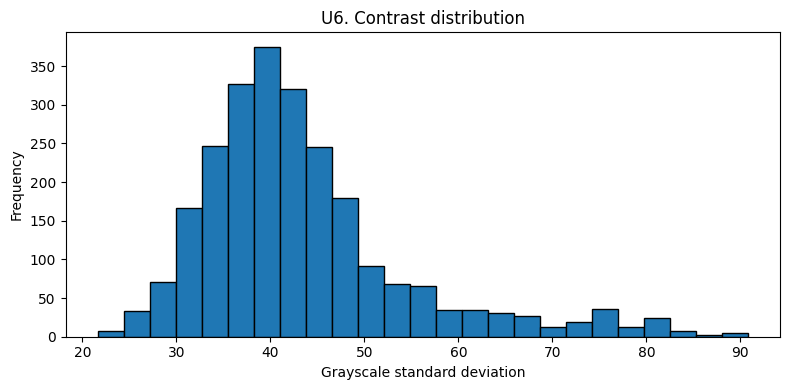

INSIGHT — U6 — Contrast
Finding: Contrast standard deviation median=41.0; 10th–90th percentile range=32.2–57.6.
Potential positive business impact: Contrast profiling supports image-quality checks and consistent preprocessing.
Potential negative impact / risk: Very low-contrast or extreme images may be harder to classify; quantify model errors before making exclusions.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(8,4)); plt.hist(stats_df.contrast,bins=25,edgecolor="black"); show("U6. Contrast distribution","Grayscale standard deviation","Frequency")


report_insight("U6 — Contrast",
    f"Contrast standard deviation median={stats_df.contrast.median():.1f}; 10th–90th percentile range={stats_df.contrast.quantile(.1):.1f}–{stats_df.contrast.quantile(.9):.1f}.",
    "Contrast profiling supports image-quality checks and consistent preprocessing.",
    "Very low-contrast or extreme images may be harder to classify; quantify model errors before making exclusions.")


### B1 — Class counts by split

**Why this chart?** Grouped bars show whether classes appear in each split in similar proportions. Missing or skewed classes can make validation/test estimates misleading.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

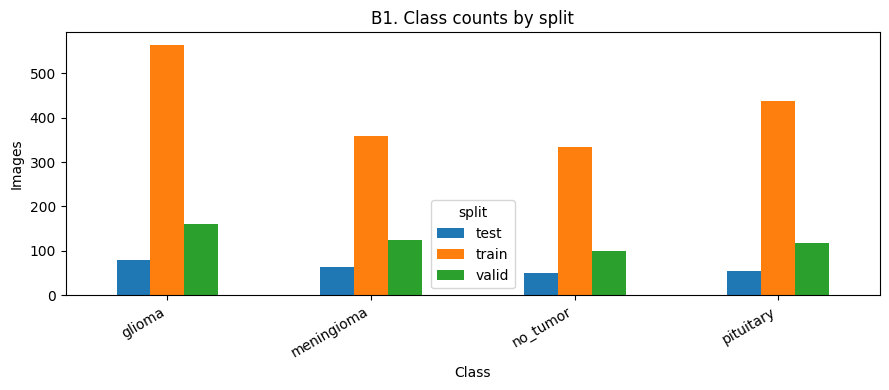

Class proportions by split (%):


,label,glioma,meningioma,no_tumor,pituitary
split,split,,,,
test,test,32.5,25.6,19.9,22.0
train,train,33.3,21.1,19.8,25.8
valid,valid,32.1,24.7,19.7,23.5


INSIGHT — B1 — Class counts by split
Finding: Largest across-split range in any class proportion is 4.5 percentage points.
Potential positive business impact: Similar proportions across splits support a fairer validation/test comparison.
Potential negative impact / risk: Large proportion shifts can make performance differences reflect split composition rather than model quality.
------------------------------------------------------------------------------------------


In [ ]:
pivot=df.groupby(["label","split"]).size().unstack(fill_value=0); pivot.plot(kind="bar",figsize=(9,4)); show("B1. Class counts by split","Class","Images",30)


_split_props = df.groupby(["split","label"]).size().groupby(level=0).apply(lambda s: s/s.sum()).unstack(fill_value=0)
print("Class proportions by split (%):")
display((_split_props*100).round(1))
_diff = (_split_props.max(axis=0)-_split_props.min(axis=0)).max()*100
report_insight("B1 — Class counts by split",
    f"Largest across-split range in any class proportion is {_diff:.1f} percentage points.",
    "Similar proportions across splits support a fairer validation/test comparison.",
    "Large proportion shifts can make performance differences reflect split composition rather than model quality.")


### B2 — Brightness by class

**Why this chart?** Boxplots compare brightness across classes. Class-specific shifts may indicate image-source artifacts rather than disease signal; test on diverse data before deployment.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

/tmp/ipykernel_543/2859704490.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  order=sorted(stats_df.label.unique()); plt.figure(figsize=(9,4)); plt.boxplot([stats_df.loc[stats_df.label==c,"brightness"] for c in order],labels=order); show("B2. Brightness by class","Class","Mean brightness",30)


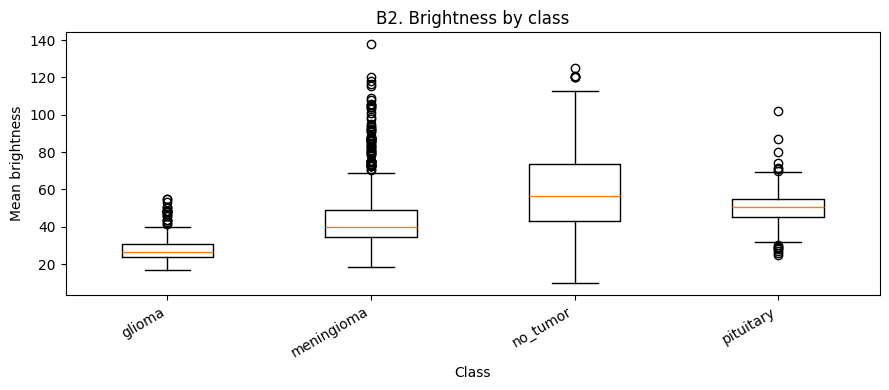

INSIGHT — B2 — Brightness by class
Finding: Median brightness by class: glioma=26.5, meningioma=40.1, pituitary=50.8, no_tumor=56.3. Median gap between highest and lowest classes=29.8.
Potential positive business impact: This can identify class-level acquisition differences that merit investigation.
Potential negative impact / risk: Brightness separation may be a shortcut signal; use validation and external data before trusting it.
------------------------------------------------------------------------------------------


In [ ]:
order=sorted(stats_df.label.unique()); plt.figure(figsize=(9,4)); plt.boxplot([stats_df.loc[stats_df.label==c,"brightness"] for c in order],labels=order); show("B2. Brightness by class","Class","Mean brightness",30)


_b = stats_df.groupby("label").brightness.median().sort_values()
report_insight("B2 — Brightness by class",
    f"Median brightness by class: " + ", ".join(f"{k}={v:.1f}" for k,v in _b.items()) + f". Median gap between highest and lowest classes={_b.max()-_b.min():.1f}.",
    "This can identify class-level acquisition differences that merit investigation.",
    "Brightness separation may be a shortcut signal; use validation and external data before trusting it.")


### B3 — Contrast by class

**Why this chart?** Boxplots compare contrast by class. Outliers can flag image-quality or acquisition differences; robust preprocessing may improve stability.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

/tmp/ipykernel_543/2182278463.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  order=sorted(stats_df.label.unique()); plt.figure(figsize=(9,4)); plt.boxplot([stats_df.loc[stats_df.label==c,"contrast"] for c in order],labels=order); show("B3. Contrast by class","Class","Contrast standard deviation",30)


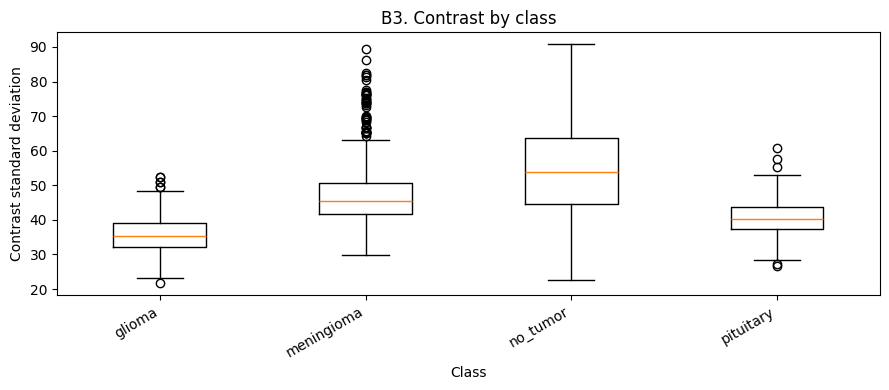

INSIGHT — B3 — Contrast by class
Finding: Median contrast by class: glioma=35.4, pituitary=40.3, meningioma=45.3, no_tumor=53.9. Median gap=18.5.
Potential positive business impact: Contrast summaries help target quality-control checks.
Potential negative impact / risk: If class identity correlates with contrast due to dataset source, model generalization may be weak.
------------------------------------------------------------------------------------------


In [ ]:
order=sorted(stats_df.label.unique()); plt.figure(figsize=(9,4)); plt.boxplot([stats_df.loc[stats_df.label==c,"contrast"] for c in order],labels=order); show("B3. Contrast by class","Class","Contrast standard deviation",30)


_b = stats_df.groupby("label").contrast.median().sort_values()
report_insight("B3 — Contrast by class",
    f"Median contrast by class: " + ", ".join(f"{k}={v:.1f}" for k,v in _b.items()) + f". Median gap={_b.max()-_b.min():.1f}.",
    "Contrast summaries help target quality-control checks.",
    "If class identity correlates with contrast due to dataset source, model generalization may be weak.")


### B4 — Width versus height

**Why this chart?** A scatter plot shows whether image dimensions follow common aspect ratios or cluster by format. Distortion from resizing can remove useful detail.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

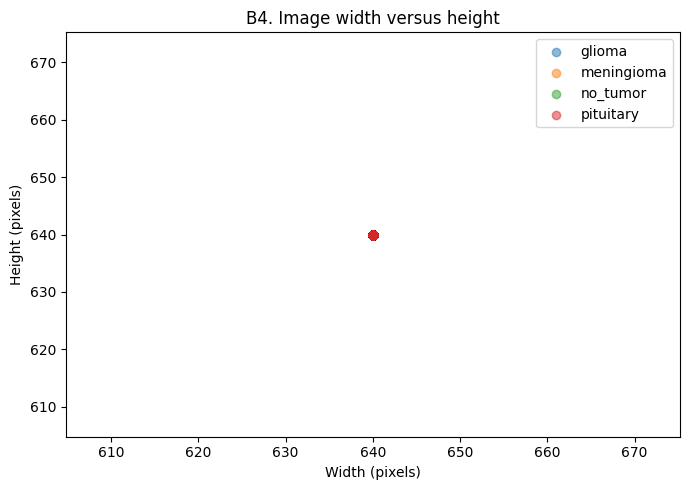

INSIGHT — B4 — Width versus height
Finding: Pearson correlation between width and height is nan; aspect-ratio median=1.000.
Potential positive business impact: Understanding dimension relationships helps select resizing and aspect-ratio handling.
Potential negative impact / risk: Distorting aspect ratio can alter anatomical structures and degrade classification.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(7,5));
for label,g in stats_df.groupby("label"): plt.scatter(g.width,g.height,alpha=.5,label=label)
plt.legend(); show("B4. Image width versus height","Width (pixels)","Height (pixels)")


_corr = stats_df[["width","height"]].corr().iloc[0,1]
report_insight("B4 — Width versus height",
    f"Pearson correlation between width and height is {_corr:.3f}; aspect-ratio median={stats_df.aspect_ratio.median():.3f}.",
    "Understanding dimension relationships helps select resizing and aspect-ratio handling.",
    "Distorting aspect ratio can alter anatomical structures and degrade classification.")


### B5 — File size by class

**Why this chart?** Boxplots compare storage size across classes. Differences may reflect compression/resolution artifacts, not biology; the chart can guide storage planning and data-quality checks.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

/tmp/ipykernel_543/1976302742.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  order=sorted(stats_df.label.unique()); plt.figure(figsize=(9,4)); plt.boxplot([stats_df.loc[stats_df.label==c,"file_size_kb"] for c in order],labels=order); show("B5. File size by class","Class","File size (KB)",30)


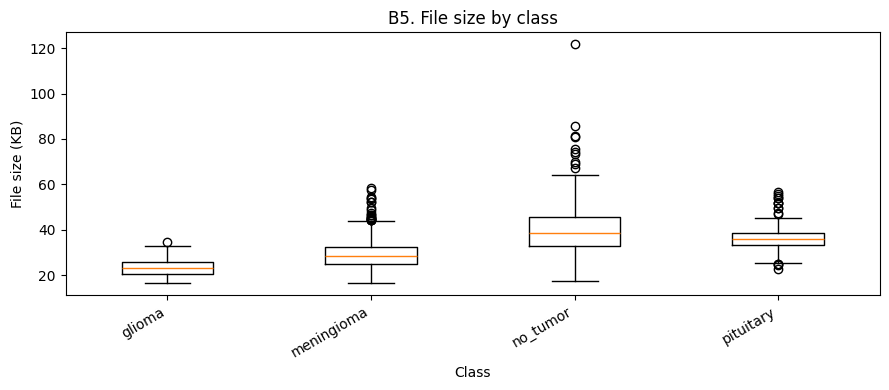

INSIGHT — B5 — File size by class
Finding: Median file size by class (KB): glioma=23.1, meningioma=28.3, pituitary=36.1, no_tumor=38.7.
Potential positive business impact: File-size patterns help estimate storage needs and flag inconsistent image encoding.
Potential negative impact / risk: File size may act as a dataset-source shortcut; it should not be treated as a tumor signal.
------------------------------------------------------------------------------------------


In [ ]:
order=sorted(stats_df.label.unique()); plt.figure(figsize=(9,4)); plt.boxplot([stats_df.loc[stats_df.label==c,"file_size_kb"] for c in order],labels=order); show("B5. File size by class","Class","File size (KB)",30)


_m = stats_df.groupby("label").file_size_kb.median().sort_values()
report_insight("B5 — File size by class",
    f"Median file size by class (KB): " + ", ".join(f"{k}={v:.1f}" for k,v in _m.items()) + ".",
    "File-size patterns help estimate storage needs and flag inconsistent image encoding.",
    "File size may act as a dataset-source shortcut; it should not be treated as a tumor signal.")


### M1 — Brightness versus contrast by class

**Why this chart?** A multivariate scatter plot shows overlap in two low-level image features across classes. Strong separation may suggest shortcuts; verify generalization carefully.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

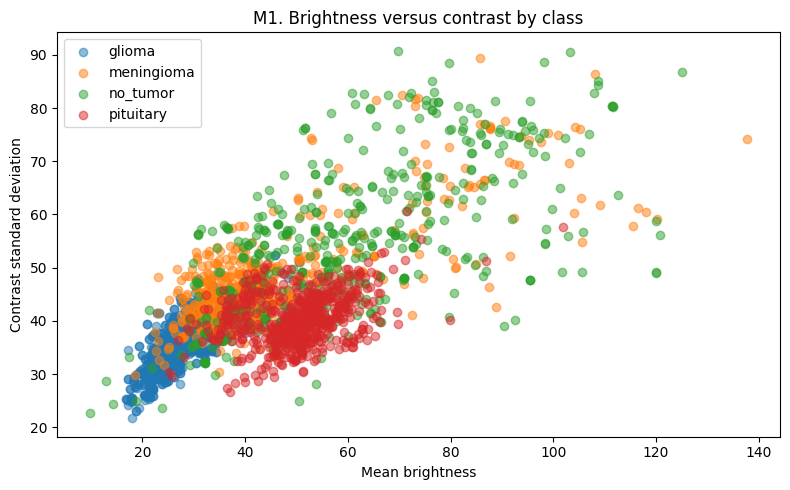

INSIGHT — M1 — Brightness versus contrast by class
Finding: Overall brightness/contrast correlation is 0.740. Class medians: glioma: brightness=26.5, contrast=35.4; meningioma: brightness=40.1, contrast=45.3; no_tumor: brightness=56.3, contrast=53.9; pituitary: brightness=50.8, contrast=40.3.
Potential positive business impact: The plot can reveal overlapping image characteristics and potential preprocessing needs.
Potential negative impact / risk: If low-level statistics appear to separate classes, a model may exploit artifacts instead of anatomy.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(8,5));
for label,g in stats_df.groupby("label"): plt.scatter(g.brightness,g.contrast,alpha=.5,label=label)
plt.legend(); show("M1. Brightness versus contrast by class","Mean brightness","Contrast standard deviation")


_corr = stats_df[["brightness","contrast"]].corr().iloc[0,1]
report_insight("M1 — Brightness versus contrast by class",
    f"Overall brightness/contrast correlation is {_corr:.3f}. Class medians: " + "; ".join(f"{k}: brightness={v.brightness:.1f}, contrast={v.contrast:.1f}" for k,v in stats_df.groupby("label")[["brightness","contrast"]].median().iterrows()) + ".",
    "The plot can reveal overlapping image characteristics and potential preprocessing needs.",
    "If low-level statistics appear to separate classes, a model may exploit artifacts instead of anatomy.")


### M2 — Brightness versus contrast by split

**Why this chart?** Color-coded splits help reveal distribution shift between training, validation, and test. Split-specific clusters can weaken the validity of model comparison.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

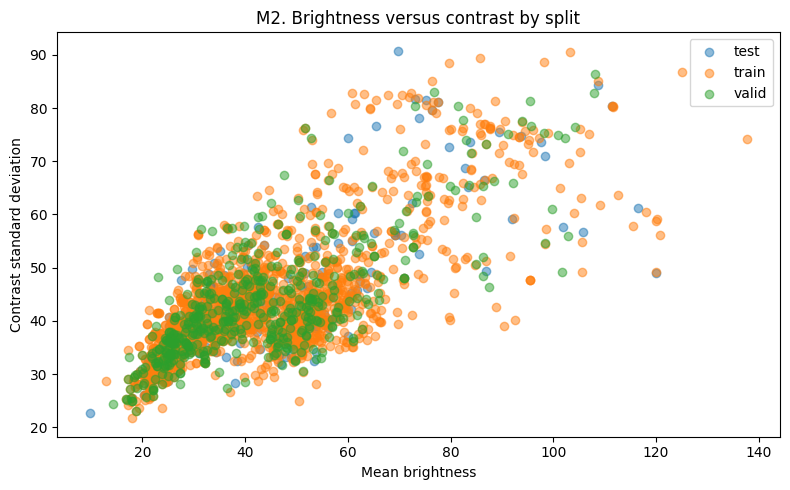

INSIGHT — M2 — Brightness versus contrast by split
Finding: Mean brightness/contrast by split: test: brightness=44.8, contrast=43.9; train: brightness=43.8, contrast=43.4; valid: brightness=43.2, contrast=43.2.
Potential positive business impact: Similar distributions across splits support more consistent evaluation.
Potential negative impact / risk: Distribution shifts between splits can inflate or depress evaluation metrics.
------------------------------------------------------------------------------------------


In [ ]:
plt.figure(figsize=(8,5));
for split,g in stats_df.groupby("split"): plt.scatter(g.brightness,g.contrast,alpha=.5,label=split)
plt.legend(); show("M2. Brightness versus contrast by split","Mean brightness","Contrast standard deviation")


_splitmed = stats_df.groupby("split")[["brightness","contrast"]].mean()
report_insight("M2 — Brightness versus contrast by split",
    "Mean brightness/contrast by split: " + "; ".join(f"{k}: brightness={v.brightness:.1f}, contrast={v.contrast:.1f}" for k,v in _splitmed.iterrows()) + ".",
    "Similar distributions across splits support more consistent evaluation.",
    "Distribution shifts between splits can inflate or depress evaluation metrics.")


### M3 — Representative MRI images

**Why this chart?** A grid enables visual inspection of class folders, image variety, and obvious labeling problems. Human visual checks support data quality but do not establish clinical correctness.

**Business impact / growth risk:** Use the observed output to determine whether data quality, imbalance, or distribution differences could affect reliability. Do not infer clinical significance from EDA alone.

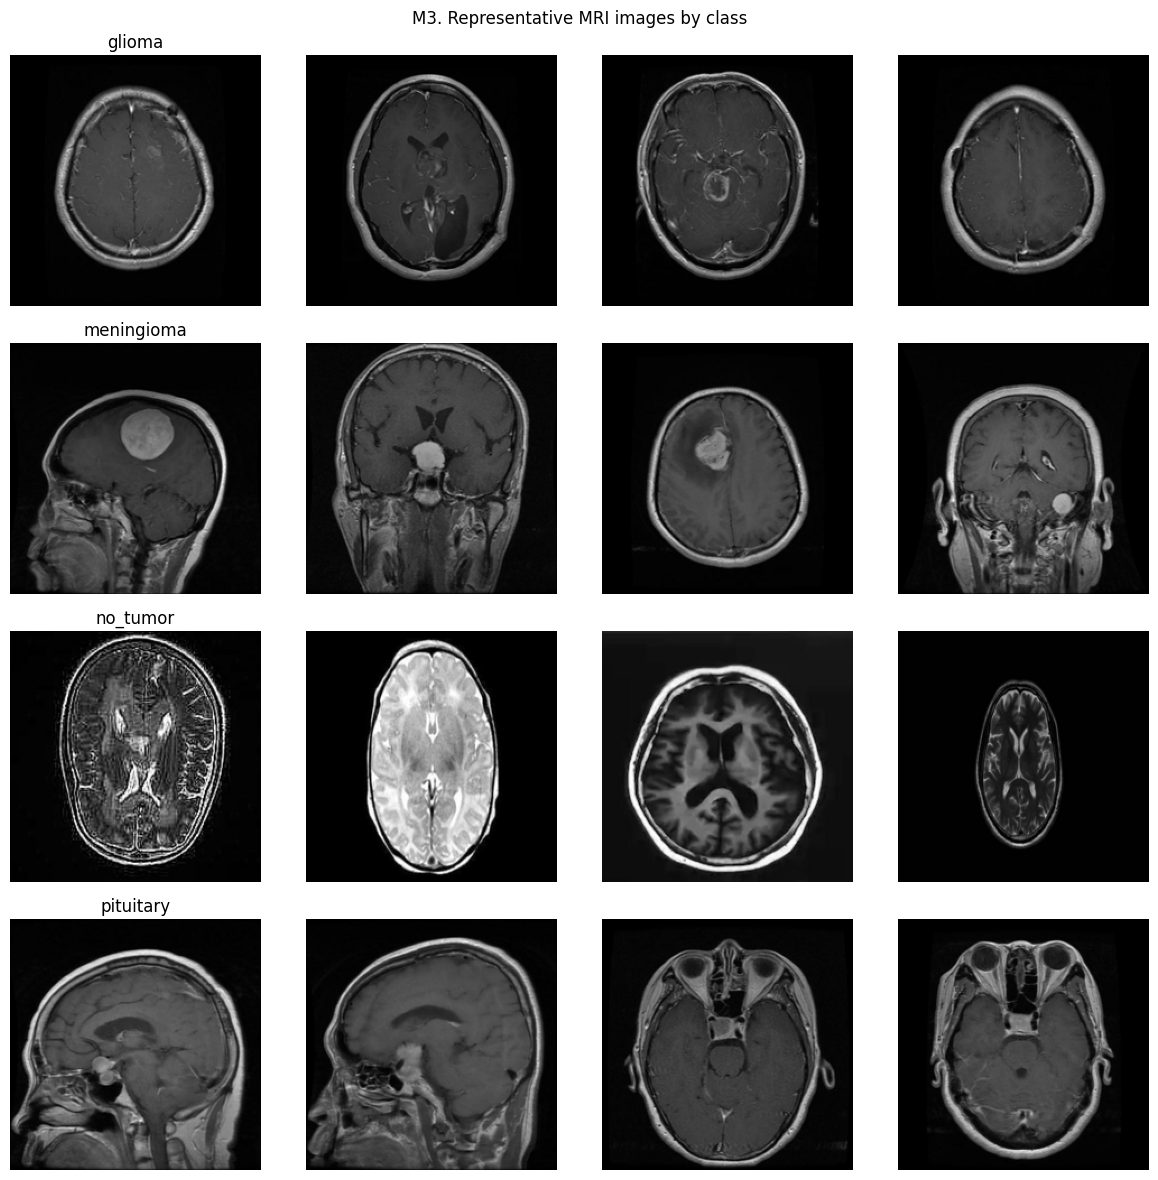

INSIGHT — M3 — Representative MRI images
Finding: Available image counts by class: no_tumor=483, meningioma=545, pituitary=610, glioma=805. Review the grid for label consistency, artifacts, and obvious duplicates; visual inspection alone cannot validate medical labels.
Potential positive business impact: Manual quality review may identify data issues before training.
Potential negative impact / risk: A visually plausible sample does not prove label correctness or clinical validity.
------------------------------------------------------------------------------------------


In [ ]:
classes=sorted(df.label.unique()); ncols=4
fig,axes=plt.subplots(len(classes),ncols,figsize=(12,3*len(classes))); axes=np.array(axes).reshape(len(classes),ncols)
for i,c in enumerate(classes):
 paths=df[df.label==c].sample(n=min(ncols,int((df.label==c).sum())),random_state=SEED).path.tolist()
 for j,ax in enumerate(axes[i]):
  ax.axis("off")
  if j<len(paths):
   try:
    with Image.open(paths[j]) as im: ax.imshow(im.convert("RGB").resize((224,224)))
    ax.set_title(c if j==0 else "")
   except (OSError,ValueError): pass
fig.suptitle("M3. Representative MRI images by class"); plt.tight_layout(); plt.show()


_sample_counts = df.groupby("label").size().sort_values()
report_insight("M3 — Representative MRI images",
    "Available image counts by class: " + ", ".join(f"{k}={v}" for k,v in _sample_counts.items()) + ". Review the grid for label consistency, artifacts, and obvious duplicates; visual inspection alone cannot validate medical labels.",
    "Manual quality review may identify data issues before training.",
    "A visually plausible sample does not prove label correctness or clinical validity.")


# Optional deep-learning training and evaluation
Set `RUN_MODEL_TRAINING = True` in Section 2 after EDA completes. Training requires TensorFlow. The training code uses train for fitting, validation for early stopping, and test only for final evaluation. If the archive structure does not expose class-named subfolders directly, inspect `SPLIT_DIRS` before training.

In [ ]:
# 6. TensorFlow import is optional for EDA
TF_AVAILABLE = False
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    TF_AVAILABLE = True
    print("TensorFlow version:", tf.__version__)
except ImportError:
    print("TensorFlow is unavailable. For training, run %pip install -q tensorflow, restart runtime, and rerun.")


TensorFlow version: 2.21.0


In [ ]:
# 7. Find each split directory that directly contains class subfolders
def find_class_root(root):
    known = {"glioma","meningioma","pituitary","no_tumor","notumor"}
    candidates = [Path(root)] + [p for p in Path(root).rglob("*") if p.is_dir()]
    for candidate in candidates:
        try:
            children = {p.name.lower().replace(" ","_") for p in candidate.iterdir() if p.is_dir()}
            if len(children.intersection(known)) >= 2:
                return candidate
        except OSError:
            pass
    return Path(root)

CLASS_ROOTS = {split: find_class_root(root) for split,root in SPLIT_DIRS.items()}
print("Class roots:", CLASS_ROOTS)


Class roots: {'train': PosixPath('/content/brain_tumor_extracted/train/train'), 'valid': PosixPath('/content/brain_tumor_extracted/valid/valid'), 'test': PosixPath('/content/brain_tumor_extracted/test/test')}


Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.
Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 14s 125ms/step - accuracy: 0.5965 - loss: 1.0183 - val_accuracy: 0.2351 - val_loss: 1.4759
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.6708 - loss: 0.8646 - val_accuracy: 0.2351 - val_loss: 1.9133
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.7080 - loss: 0.7775 - val_accuracy: 0.2351 - val_loss: 2.8606
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 33s 400ms/step - accuracy: 0.6059 - loss: 0.9464 - val_accuracy: 0.7988 - val_loss: 0.5419
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.8018 - loss: 0.5140 - val_accuracy: 0.8347 - val_loss: 0.4503
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.8342 - loss: 0.4270 - val_accuracy: 0.8745 - val_loss: 0.3791
Epoch 4/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.8684 

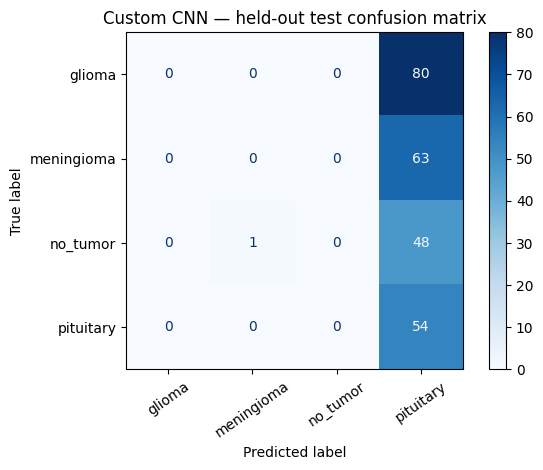


MobileNetV2 test accuracy: 0.8780
              precision    recall  f1-score   support

      glioma       0.88      0.95      0.92        80
  meningioma       0.88      0.68      0.77        63
    no_tumor       0.90      0.88      0.89        49
   pituitary       0.86      1.00      0.92        54

    accuracy                           0.88       246
   macro avg       0.88      0.88      0.87       246
weighted avg       0.88      0.88      0.87       246



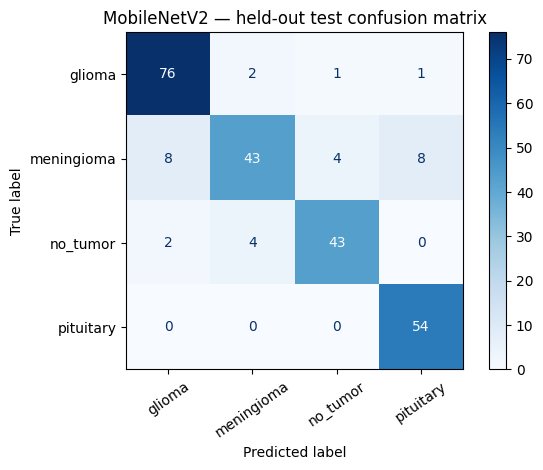

,model,test_accuracy
0,Custom CNN,0.219512
1,MobileNetV2,0.878049


In [ ]:
# 8. Train and evaluate models (runs only when explicitly enabled)
if not RUN_MODEL_TRAINING:
    print("Training skipped. Set RUN_MODEL_TRAINING=True in Section 2 to train.")
elif not TF_AVAILABLE:
    print("Training skipped: TensorFlow is not installed.")
else:
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = keras.utils.image_dataset_from_directory(CLASS_ROOTS["train"], image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, label_mode="int", seed=SEED)
    valid_ds = keras.utils.image_dataset_from_directory(CLASS_ROOTS["valid"], image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, label_mode="int", shuffle=False)
    test_ds = keras.utils.image_dataset_from_directory(CLASS_ROOTS["test"], image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, label_mode="int", shuffle=False)
    class_names = train_ds.class_names
    if valid_ds.class_names != class_names or test_ds.class_names != class_names:
        raise ValueError("Train/validation/test class folders differ. Ensure all splits contain the same classes.")
    num_classes = len(class_names)
    train_ds = train_ds.prefetch(AUTOTUNE)
    valid_ds = valid_ds.prefetch(AUTOTUNE)
    test_ds = test_ds.prefetch(AUTOTUNE)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)]

    cnn = keras.Sequential([
        layers.Input(shape=(*IMAGE_SIZE,3)), layers.Rescaling(1./255),
        layers.RandomFlip("horizontal"), layers.RandomRotation(0.05),
        layers.Conv2D(32,3,padding="same",activation="relu"), layers.MaxPooling2D(),
        layers.BatchNormalization(), layers.Conv2D(64,3,padding="same",activation="relu"),
        layers.MaxPooling2D(), layers.BatchNormalization(),
        layers.Conv2D(128,3,padding="same",activation="relu"), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(), layers.Dropout(.35),
        layers.Dense(128,activation="relu"), layers.Dropout(.25),
        layers.Dense(num_classes,activation="softmax")
    ], name="custom_cnn")
    cnn.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    hist_cnn = cnn.fit(train_ds,validation_data=valid_ds,epochs=EPOCHS,callbacks=callbacks)
    cnn.save("brain_tumor_custom_cnn.keras")

    base = keras.applications.MobileNetV2(input_shape=(*IMAGE_SIZE,3),include_top=False,weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape=(*IMAGE_SIZE,3))
    x = layers.Rescaling(1./127.5,offset=-1)(inputs)
    x = base(x,training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(.3)(x)
    outputs = layers.Dense(num_classes,activation="softmax")(x)
    transfer = keras.Model(inputs,outputs,name="mobilenetv2_transfer")
    transfer.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    hist_transfer = transfer.fit(train_ds,validation_data=valid_ds,epochs=EPOCHS,callbacks=callbacks)
    transfer.save("brain_tumor_mobilenetv2.keras")

    def evaluate(model, dataset, name):
        y_true = np.concatenate([y.numpy() for _,y in dataset])
        pred = model.predict(dataset,verbose=0).argmax(axis=1)
        print(f"\n{name} test accuracy: {accuracy_score(y_true,pred):.4f}")
        print(classification_report(y_true,pred,target_names=class_names,zero_division=0))
        ConfusionMatrixDisplay(confusion_matrix(y_true,pred),display_labels=class_names).plot(xticks_rotation=35,cmap="Blues")
        plt.title(name + " — held-out test confusion matrix")
        plt.tight_layout(); plt.show()
        return {"model":name,"test_accuracy":accuracy_score(y_true,pred)}
    comparison = pd.DataFrame([evaluate(cnn,test_ds,"Custom CNN"),evaluate(transfer,test_ds,"MobileNetV2")])
    display(comparison)
    comparison.to_csv("model_comparison.csv",index=False)


In [37]:
# Verify the full test-set metrics for the currently loaded MobileNetV2 model.

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

probabilities = transfer.predict(test_ds, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("Full test accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
))

Full test accuracy: 0.878

Classification report:
              precision    recall  f1-score   support

      glioma       0.88      0.95      0.92        80
  meningioma       0.88      0.68      0.77        63
    no_tumor       0.90      0.88      0.89        49
   pituitary       0.86      1.00      0.92        54

    accuracy                           0.88       246
   macro avg       0.88      0.88      0.87       246
weighted avg       0.88      0.88      0.87       246


Confusion matrix:
[[76  2  1  1]
 [ 8 43  4  8]
 [ 2  4 43  0]
 [ 0  0  0 54]]


In [ ]:
# 9. Export deployment artifacts (run after successful model training)
# This saves the selected MobileNetV2 model, class order, and evaluation artifacts.
from pathlib import Path
import json
import shutil
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

ARTIFACT_DIR = Path("/content/brain_tumor_submission") if Path("/content").exists() else Path.cwd() / "brain_tumor_submission"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

if "transfer" not in globals():
    raise RuntimeError(
        "The MobileNetV2 model is not in memory. Run the model-training cell first "
        "with RUN_MODEL_TRAINING=True."
    )

# Save the selected model in Keras format.
transfer.save(ARTIFACT_DIR / "brain_tumor_mobilenetv2.keras")

# Persist the exact alphabetical label order used by image_dataset_from_directory.
with open(ARTIFACT_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, indent=2)

# Recompute final metrics on the held-out test set for reproducibility.
y_true_final = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob_final = transfer.predict(test_ds, verbose=0)
y_pred_final = np.argmax(y_prob_final, axis=1)

metrics = {
    "selected_model": "MobileNetV2",
    "test_images": int(len(y_true_final)),
    "test_accuracy": float(accuracy_score(y_true_final, y_pred_final)),
    "class_names": list(class_names),
    "medical_disclaimer": (
        "Educational prototype only; not clinically validated and not for diagnosis or treatment."
    )
}
with open(ARTIFACT_DIR / "evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

report = classification_report(
    y_true_final,
    y_pred_final,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).transpose().to_csv(ARTIFACT_DIR / "classification_report.csv")
pd.DataFrame(
    confusion_matrix(y_true_final, y_pred_final, labels=np.arange(len(class_names))),
    index=class_names,
    columns=class_names
).to_csv(ARTIFACT_DIR / "confusion_matrix.csv")

# Include the application files if they are uploaded beside this notebook; otherwise print instructions.
print("Deployment artifacts saved to:", ARTIFACT_DIR)
print("Files:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))
print("Download the .keras model, class_names.json, evaluation_summary.json, and CSV files before ending Colab.")


# Final submission checklist
- [ ] Run all EDA cells and inspect all 14 charts.
- [ ] Write conclusions based on actual chart outputs, including class distribution, split consistency, image resolution, brightness/contrast, and quality.
- [ ] If training is enabled, save actual test metrics, classification reports, confusion matrices, and model comparison.
- [ ] Download the executed notebook and `.keras` model files from the runtime.
- [ ] Keep `app.py`, `requirements.txt`, `class_names.json`, and the saved MobileNetV2 model together before running `streamlit run app.py`.
- [ ] Run the deployment export cell and download all generated artifacts.
- [ ] Include a README with setup instructions and the medical-use disclaimer.

**Deployment note:** Colab files are temporary. Download the executed notebook, trained models, and results before disconnecting. This model is not clinically validated and must not be used for diagnosis.

### Conclusion

The Brain Tumor MRI Image Classification project compared a custom Convolutional Neural Network (CNN) with a transfer-learning model based on MobileNetV2 to classify MRI images into four categories: glioma, meningioma, no tumor, and pituitary.

The MobileNetV2 model achieved **87.80% test accuracy** on a held-out dataset of 246 images, with a macro F1-score of 0.87. Its class-wise recall was 95% for glioma, 68.25% for meningioma, 87.76% for no tumor, and 100% for pituitary. The confusion matrix revealed that meningioma was the most challenging category, with misclassifications primarily involving glioma and pituitary.

The custom CNN failed to distinguish the four classes and predominantly predicted pituitary, achieving only 21.95% test accuracy. Consequently, MobileNetV2 was selected as the preferred experimental model.

The results demonstrate the potential value of transfer learning for MRI image classification. However, the evaluation is limited to the available dataset and does not establish clinical reliability. Further validation on independent, representative data and appropriate clinical review would be required before any real-world medical use. The system is an educational prototype and is not intended for diagnosis or treatment decisions.